<a href="https://colab.research.google.com/github/utjimmyx/python/blob/main/csub_review_analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# CSUB Google Maps Reviews: Text Analysis in Colab
Pipeline: parse the raw scraped text → clean → language check → sentiment (VADER) → word/bigram frequencies → word cloud → topic model (NMF) → rule-based theme tagging → export.

**Note:** the scrape has no star ratings, so sentiment scores are a proxy, not a rating.

In [ ]:
!pip -q install vaderSentiment wordcloud langdetect

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 981.5/981.5 kB 10.7 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 126.0/126.0 kB 5.0 MB/s eta 0:00:00


In [ ]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from collections import Counter

from langdetect import detect, DetectorFactory
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer
from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer, ENGLISH_STOP_WORDS
from sklearn.decomposition import NMF
from wordcloud import WordCloud

DetectorFactory.seed = 42
pd.set_option("display.max_colwidth", 120)

## 1. Load the file

In [ ]:
try:
    from google.colab import files
    uploaded = files.upload()              # choose review_CSUB.txt
    fname = list(uploaded.keys())[0]
except ImportError:                        # running outside Colab
    fname = "review_CSUB.txt"

with open(fname, encoding="utf-8", errors="ignore") as f:
    raw = f.read()
print(f"{len(raw):,} characters loaded")

Saving review_CSUB.txt to review_CSUB.txt
7,706 characters loaded


## 2. Parse raw text into one row per review
Rules: the first line (`text`) is a header; a quoted block (starts with `"`, ends with `"`) can span blank lines and is one review; otherwise each non-blank line is one review; blank lines are separators.

In [ ]:
def parse_reviews(raw):
    lines = raw.replace("\r", "").split("\n")
    if lines and lines[0].strip().lower() == "text":
        lines = lines[1:]

    reviews, buf, in_quote = [], [], False
    for line in lines:
        s = line.strip()
        if in_quote:
            buf.append(s)
            if s.endswith('"'):
                reviews.append(" ".join(b for b in buf if b))
                buf, in_quote = [], False
            continue
        if not s:
            continue
        if s.startswith('"') and not (s.endswith('"') and len(s) > 1):
            in_quote, buf = True, [s]
        else:
            reviews.append(s)
    if buf:                                 # unclosed quote at EOF
        reviews.append(" ".join(b for b in buf if b))

    cleaned = []
    for r in reviews:
        r = r.strip().strip('"').replace('""', '"')
        r = re.sub(r"\s+", " ", r).strip()
        if r:
            cleaned.append(r)
    return cleaned

reviews = parse_reviews(raw)
df = pd.DataFrame({"review": reviews})
df["review_id"] = np.arange(1, len(df) + 1)
df["n_words"] = df["review"].str.split().str.len()
print(f"{len(df)} reviews parsed")
df.head(10)

39 reviews parsed


,review,review_id,n_words
0,its a nice campus. I enjoy the many trees,1,9
1,Loving it!!!,2,2
2,Definitely the place to go if you want to be A student. It's all about project rebound woo woo. Giving opportunities...,3,47
3,"very low care for students, it's impossible to speak to any one, log the website is constantly down. the staff just ...",4,47
4,Es muy grande la universidad y tienen muy buena ubicación,5,10
5,Used Alumni park for a prom session. The young thought it was perfect. Two small bridges and a small stream. Very be...,6,22
6,Great University!,7,2
7,Love it,8,2
8,Horrible experience,9,2
9,I don’t like math and that’s why I didn’t complete the assignment at Bakersfield college. I have a PHD in sales. Ret...,10,32


## 3. Language detection

In [ ]:
def safe_lang(t):
    try:
        return detect(t)
    except Exception:
        return "unknown"

df["lang"] = df["review"].apply(safe_lang)
print(df["lang"].value_counts())
# Short snippets ("Love it") are unreliable for language detection, so treat them as English.
df["is_english"] = (df["lang"] == "en") | (df["n_words"] < 5)
print("\nNon-English / excluded:")
print(df.loc[~df["is_english"], ["review", "lang"]])
df_en = df[df["is_english"]].copy()          # VADER is English-only
print(f"\n{len(df_en)} English reviews kept for sentiment/topic analysis")

lang
en    36
es     2
ro     1
Name: count, dtype: int64

Non-English / excluded:
                                                      review lang
4  Es muy grande la universidad y tienen muy buena ubicación   es

38 English reviews kept for sentiment/topic analysis


## 4. Sentiment (VADER)

sentiment
positive    31
negative     7
neutral      0
Name: count, dtype: int64

Mean compound score: 0.412


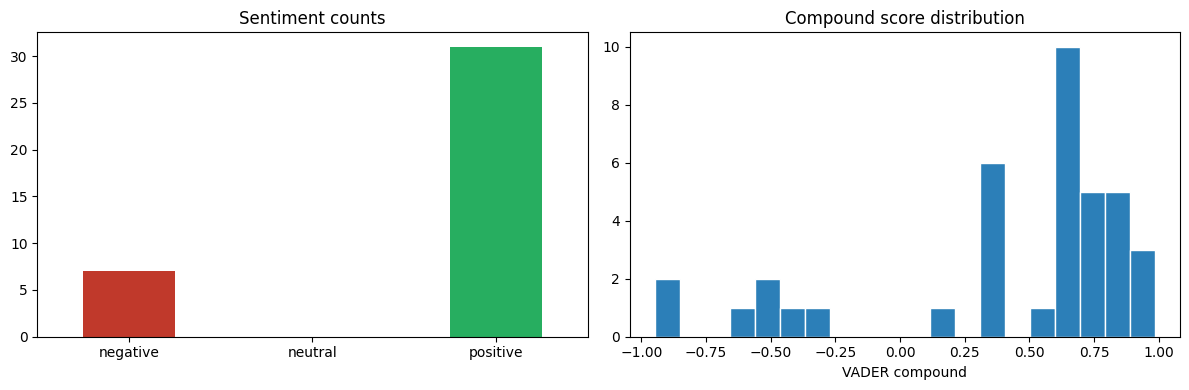

In [ ]:
sia = SentimentIntensityAnalyzer()
df_en["compound"] = df_en["review"].apply(lambda t: sia.polarity_scores(t)["compound"])
df_en["sentiment"] = pd.cut(df_en["compound"], bins=[-1.01, -0.05, 0.05, 1.01],
                            labels=["negative", "neutral", "positive"])

print(df_en["sentiment"].value_counts())
print(f"\nMean compound score: {df_en['compound'].mean():.3f}")

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
df_en["sentiment"].value_counts().reindex(["negative", "neutral", "positive"]).plot(
    kind="bar", ax=ax[0], color=["#c0392b", "#95a5a6", "#27ae60"])
ax[0].set_title("Sentiment counts"); ax[0].set_xlabel(""); ax[0].tick_params(axis="x", rotation=0)
ax[1].hist(df_en["compound"], bins=20, color="#2c7fb8", edgecolor="white")
ax[1].set_title("Compound score distribution"); ax[1].set_xlabel("VADER compound")
plt.tight_layout(); plt.show()

In [ ]:
print("Most negative:")
display(df_en.nsmallest(5, "compound")[["review", "compound"]])
print("Most positive:")
display(df_en.nlargest(5, "compound")[["review", "compound"]])

## 5. Text cleaning, top words, and bigrams

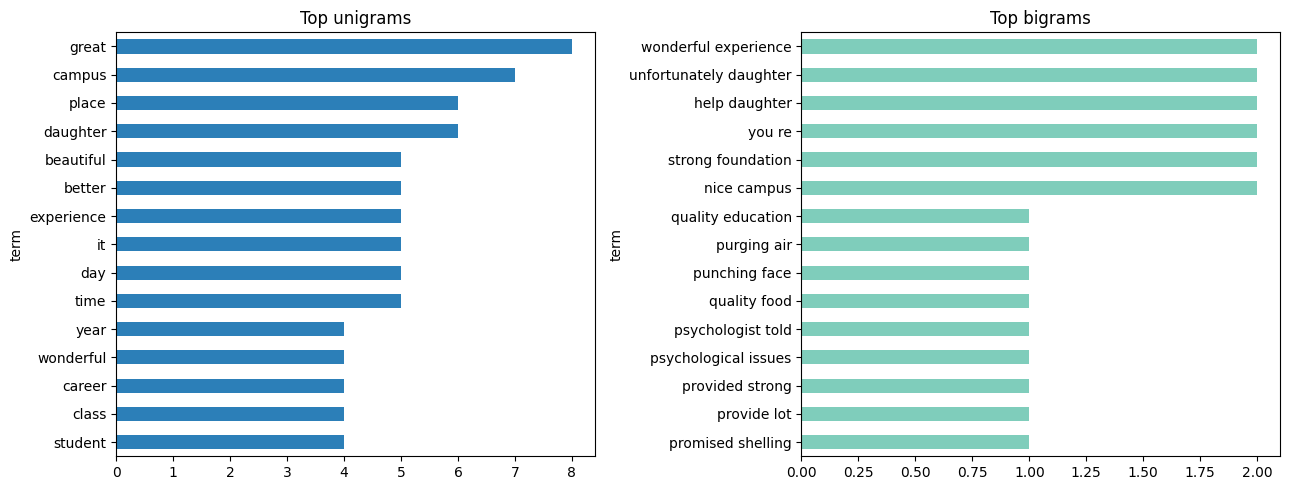

In [ ]:
custom_stop = {"csub", "bakersfield", "university", "school", "college", "just", "like", "don", "ve", "ll"}
stop = set(ENGLISH_STOP_WORDS) | custom_stop

def clean_text(t):
    t = t.lower()
    t = re.sub(r"http\S+", " ", t)
    t = re.sub(r"[^a-z\s']", " ", t)
    t = re.sub(r"\s+", " ", t).strip()
    return " ".join(w for w in t.split() if w not in stop and len(w) > 2)

df_en["clean"] = df_en["review"].apply(clean_text)

def top_ngrams(texts, ngram=(1, 1), n=15):
    cv = CountVectorizer(ngram_range=ngram)
    X = cv.fit_transform(texts)
    freq = np.asarray(X.sum(axis=0)).ravel()
    return (pd.DataFrame({"term": cv.get_feature_names_out(), "count": freq})
              .sort_values("count", ascending=False).head(n))

uni = top_ngrams(df_en["clean"], (1, 1))
bi  = top_ngrams(df_en["clean"], (2, 2))

fig, ax = plt.subplots(1, 2, figsize=(13, 5))
uni.iloc[::-1].plot.barh(x="term", y="count", ax=ax[0], legend=False, color="#2c7fb8")
ax[0].set_title("Top unigrams")
bi.iloc[::-1].plot.barh(x="term", y="count", ax=ax[1], legend=False, color="#7fcdbb")
ax[1].set_title("Top bigrams")
plt.tight_layout(); plt.show()

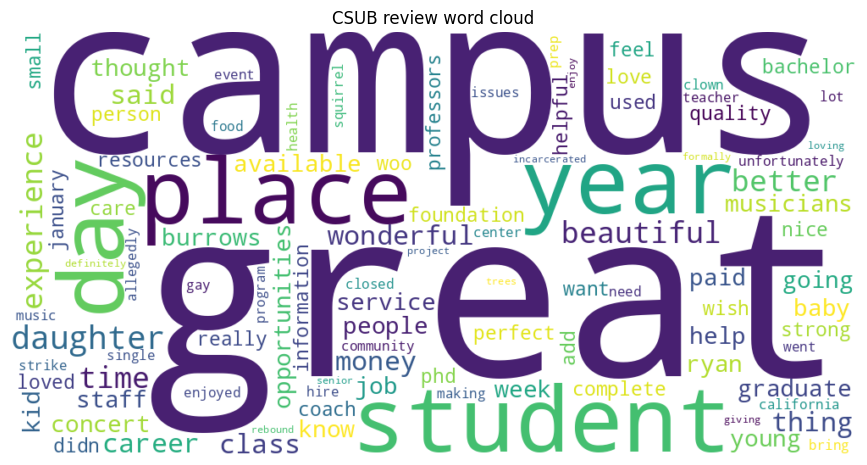

In [ ]:
wc = WordCloud(width=1000, height=500, background_color="white", colormap="viridis",
               max_words=100, random_state=42).generate(" ".join(df_en["clean"]))
plt.figure(figsize=(11, 5.5)); plt.imshow(wc, interpolation="bilinear"); plt.axis("off")
plt.title("CSUB review word cloud"); plt.show()

## 6. Topic modeling (NMF on TF-IDF)
The sample is small, so keep `n_topics` low and treat the topics as exploratory.

In [ ]:
n_topics = 4
tfidf = TfidfVectorizer(min_df=2, max_df=0.8, ngram_range=(1, 2))
X = tfidf.fit_transform(df_en["clean"])

nmf = NMF(n_components=n_topics, random_state=42, init="nndsvda", max_iter=500)
W = nmf.fit_transform(X)
terms = tfidf.get_feature_names_out()

for k, comp in enumerate(nmf.components_):
    top = [terms[i] for i in comp.argsort()[::-1][:8]]
    print(f"Topic {k+1}: {', '.join(top)}")

df_en["topic"] = W.argmax(axis=1) + 1
df_en.groupby("topic").agg(n=("review", "size"), mean_sentiment=("compound", "mean")).round(3)

Topic 1: great, musicians, enjoyed, time, young, information, things, paid
Topic 2: wonderful, experience, wonderful experience, loved, things, information, paid, musicians
Topic 3: campus, nice campus, nice, love, beautiful, thought, young, food
Topic 4: it, staff, better, year, place, time, career, student


,n,mean_sentiment
topic,,
1,7,0.544
2,4,0.376
3,8,0.493
4,19,0.337


## 7. Rule-based theme tagging

,n_reviews,mean_sentiment
Admin / Support,10,0.193
Campus / Facilities,10,0.366
Academics / Faculty,8,0.205
Events / Performances,8,0.594
Cost / Value,7,0.192
Safety / Discrimination,5,0.074
Careers / Outcomes,4,0.668
Animal welfare,1,-0.898
Youth / Aquatics,1,0.510


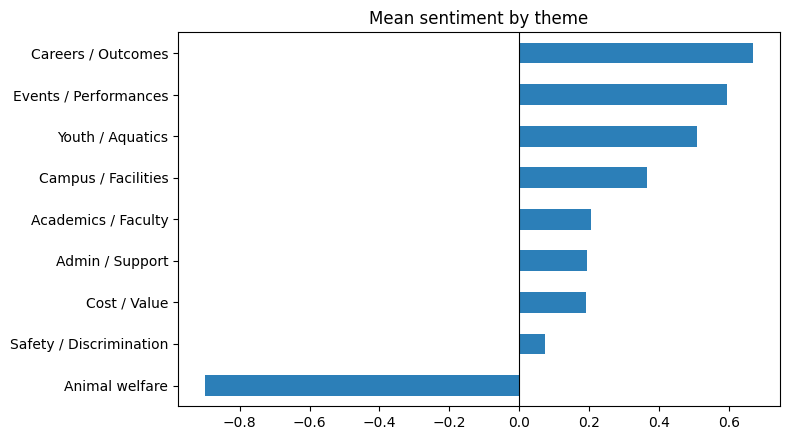

In [ ]:
themes = {
    "Academics / Faculty":   r"professor|teacher|class|classes|course|degree|program|masters|tutor|grad",
    "Admin / Support":       r"staff|support|website|email|advis|communicat|financial aid|help",
    "Safety / Discrimination": r"assault|gay|lgbt|safe|punch|fired|bash",
    "Events / Performances": r"concert|event|vivaldi|coldplay|musician|music|graduation|prom",
    "Campus / Facilities":   r"campus|library|gym|park|trees|food|parking|bridge|art|booth",
    "Cost / Value":          r"tuition|money|\$|pay|paid|expensive|checks|refund",
    "Careers / Outcomes":    r"career|job|internship|labor market|credibility",
    "Animal welfare":        r"squirrel|carbon monoxide|burrow|fumigat",
    "Youth / Aquatics":      r"aquatic|swim|coach|daughter|kids",
}

for name, pat in themes.items():
    df_en[name] = df_en["review"].str.contains(pat, case=False, regex=True)

theme_summary = pd.DataFrame({
    "n_reviews": {t: int(df_en[t].sum()) for t in themes},
    "mean_sentiment": {t: df_en.loc[df_en[t], "compound"].mean() for t in themes},
}).round(3).sort_values("n_reviews", ascending=False)
display(theme_summary)

theme_summary["mean_sentiment"].dropna().sort_values().plot.barh(
    figsize=(8, 4.5), color="#2c7fb8", title="Mean sentiment by theme")
plt.axvline(0, color="black", lw=0.8); plt.tight_layout(); plt.show()

## 8. (Optional) Transformer sentiment
Handles sarcasm and context better than VADER, but is slower. Run only if needed.

In [ ]:
# !pip -q install transformers torch
# from transformers import pipeline
# clf = pipeline("sentiment-analysis", model="cardiffnlp/twitter-roberta-base-sentiment-latest",
#                truncation=True, max_length=256)
# preds = clf(df_en["review"].tolist())
# df_en["roberta_label"] = [p["label"] for p in preds]
# df_en["roberta_score"] = [p["score"] for p in preds]
# pd.crosstab(df_en["sentiment"], df_en["roberta_label"])

## 9. Export

In [ ]:
out_cols = ["review_id", "review", "n_words", "lang", "compound", "sentiment", "topic"] + list(themes)
df_en[out_cols].to_csv("csub_reviews_analyzed.csv", index=False)
try:
    files.download("csub_reviews_analyzed.csv")
except NameError:
    pass

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>